# DNA-repair gene expression in breast tumour vs normal tissue

**Computing Bioinformatics, group project** · Strathmore University

| Member | Student ID | Notebook stages | Folder |
|---|---|---|---|
| Ibrahim Sudheysi | 166344 | 1 Question · 2 Data acquisition · 3 Preprocessing & QC | `1-ibrahim-data-qc/` |
| Alvin Kimani | 167148 | 4 Exploratory data analysis · 5 Core analysis (differential expression) | `2-alvin-eda-de/` |
| Latifah Jaafar | 167074 | 6 Biological interpretation | `3-latifah-biology/` |
| Caleb Kipchirchir | 169391 | 7 Machine learning | `4-caleb-ml/` |
| Jude Makau | 166487 | Model export & deployment (web app, API) · presentation | `5-jude-deployment/` |
| All | | 8 Conclusions · report | `REPORT.md` |

Runs top to bottom in Google Colab (about 3 minutes). It downloads its own data, and every figure and table is saved into the owner's folder.

## Setup
*Owner: Jude Makau (166487)*: packages, output folders and plotting style used by every stage.

In [1]:
# SETUP (Jude): install missing packages, import libraries, create each member's output folders, set plot style.
import sys, subprocess, importlib.util
# Install any package Colab doesn't have by default
for pkg in ["statsmodels", "adjustText", "networkx"]:
    if importlib.util.find_spec(pkg if pkg != "adjustText" else "adjustText") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# Standard libraries: files, JSON, warnings, downloads
import os, json, warnings, urllib.request
# numpy = maths on arrays, pandas = tables (DataFrames)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
# scipy.stats gives us Mann-Whitney, Wilcoxon, Fisher's exact test, Spearman correlation
from scipy import stats
# multipletests applies the Benjamini-Hochberg FDR correction
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# One output folder per team member; every figure/table is saved into its owner's folder
D1, D2, D3, D4, D5 = "1-ibrahim-data-qc", "2-alvin-eda-de", "3-latifah-biology", "4-caleb-ml", "5-jude-deployment"
for d in [D1, D2, D3, D4, D5, "data/raw"]:
    os.makedirs(d, exist_ok=True)
for d in [D1, D2, D3, D4]:
    os.makedirs(f"{d}/figures", exist_ok=True); os.makedirs(f"{d}/results", exist_ok=True)

# Colours used in every plot: blue = normal tissue, orange = tumour
NORMAL_C, TUMOUR_C, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.dpi": 90,
    "savefig.dpi": 200, "savefig.bbox": "tight", "legend.frameon": False})
# Helper: save a figure into <member folder>/figures and show it
def save(fig, folder, name):
    fig.savefig(f"{folder}/figures/{name}.png"); plt.show()
# Fixed random seed so every run gives identical results
SEED = 42

## Stage 1 · Research question and objectives
*Owner: Ibrahim Sudheysi (166344)*

**Research question.** Do breast tumour and normal breast tissues differ in the expression of DNA damage repair (DDR) genes, and can the expression of those genes alone classify a sample as tumour or normal?

**Objectives**
1. **O1:** Compare the expression of 158 curated DDR genes between tumour and normal breast tissue, with FDR-corrected tests and a patient-matched (paired) analysis.
2. **O2:** Find which repair pathways change and explain the change biologically, using pathway enrichment, a gene co-expression network and the literature.
3. **O3:** Build machine-learning classifiers that use only DDR genes, and test them against proper baselines with patient-grouped cross-validation.
4. **O4:** Deploy the final model as a tool anyone can use (GitHub Pages web app plus a REST API).

**Hypotheses**
- **H1 (O1–O2):** DDR genes, especially replication-coupled pathways (homologous recombination, Fanconi anaemia, mismatch and base excision repair), are up-regulated in tumours. H0: their expression does not differ.
- **H2 (O3):** A classifier using only DDR genes beats a majority-class baseline (ROC-AUC 0.5, balanced accuracy 0.5) and reaches ROC-AUC > 0.90. We also test whether DDR genes beat **random gene sets of the same size**, which shows whether the signal is specific to DNA repair.

## Stage 2 · Data acquisition
*Owner: Ibrahim Sudheysi (166344)*

**Source.** The Cancer Genome Atlas breast invasive carcinoma cohort (**TCGA-BRCA**, PanCancer Atlas 2018 release), taken from the public **cBioPortal datahub** (study `brca_tcga_pan_can_atlas_2018`). TCGA is the reference public cancer genomics resource from the US National Cancer Institute. cBioPortal redistributes its processed data openly.

**Why this dataset fits the question.** It has RNA-seq for primary tumours *and* adjacent normal tissue from the same patients, processed in one pipeline. That lets us compare tumour with normal within patients.

In [2]:
# STAGE 2 (Ibrahim): download the 4 TCGA-BRCA files from cBioPortal (skipped if already present) and load them.
# Public cBioPortal datahub location of the TCGA-BRCA PanCancer Atlas 2018 study
BASE = "https://media.githubusercontent.com/media/cBioPortal/datahub/master/public/brca_tcga_pan_can_atlas_2018"
# local file name -> path on the datahub
FILES = {
    "data_mrna_seq_v2_rsem.txt": "data_mrna_seq_v2_rsem.txt",
    "data_mrna_seq_v2_rsem_normal_samples.txt": "normals/data_mrna_seq_v2_rsem_normal_samples.txt",
    "data_clinical_patient.txt": "data_clinical_patient.txt",
    "data_clinical_sample.txt": "data_clinical_sample.txt",
}
# Download each file once, then print its size
for local, remote in FILES.items():
    path = f"data/raw/{local}"
    if not os.path.exists(path):
        print("downloading", local, "...")
        urllib.request.urlretrieve(f"{BASE}/{remote}", path)
    print(f"{local:45s} {os.path.getsize(path)/1e6:7.1f} MB")

# Tumour RNA-seq: rows = genes, columns = 1,082 tumour samples (barcode ending -01)
tum_raw = pd.read_csv("data/raw/data_mrna_seq_v2_rsem.txt", sep="\t")
# Normal RNA-seq: same genes, 114 normal samples (barcode ending -11)
nor_raw = pd.read_csv("data/raw/data_mrna_seq_v2_rsem_normal_samples.txt", sep="\t")
# Clinical tables: PAM50 subtype per patient, sample details (lines starting # are headers)
clin_p = pd.read_csv("data/raw/data_clinical_patient.txt", sep="\t", comment="#")
clin_s = pd.read_csv("data/raw/data_clinical_sample.txt", sep="\t", comment="#")
print("\ntumour matrix:", tum_raw.shape, " normal matrix:", nor_raw.shape)
print("clinical patient:", clin_p.shape, " clinical sample:", clin_s.shape)
# Peek at the first rows/columns to see the raw format
tum_raw.iloc[:4, :5]

data_mrna_seq_v2_rsem.txt                       154.7 MB
data_mrna_seq_v2_rsem_normal_samples.txt         16.5 MB
data_clinical_patient.txt                         0.3 MB
data_clinical_sample.txt                          0.2 MB



tumour matrix: (20531, 1084)  normal matrix: (20531, 116)
clinical patient: (1084, 38)  clinical sample: (1084, 19)


,Hugo_Symbol,Entrez_Gene_Id,TCGA-3C-AAAU-01,TCGA-3C-AALI-01,TCGA-3C-AALJ-01
0,NaN,100130426,0.0000,0.0000,0.9066
1,NaN,100133144,16.3644,9.2659,11.6228
2,UBE2Q2P2,100134869,12.9316,17.3790,9.2294
3,HMGB1P1,10357,52.1503,69.7553,154.2970


In [3]:
# STAGE 2 (Ibrahim): data dictionary - every file and variable we use, saved as a table.
data_dictionary = pd.DataFrame([
  ["data_mrna_seq_v2_rsem.txt", "Hugo_Symbol", "HGNC gene symbol (row identifier)"],
  ["data_mrna_seq_v2_rsem.txt", "Entrez_Gene_Id", "NCBI Entrez gene ID"],
  ["data_mrna_seq_v2_rsem.txt", "TCGA-XX-XXXX-01", "One column per primary tumour: RSEM-normalised RNA-seq expression (upper-quartile normalised count)"],
  ["data_mrna_seq_v2_rsem_normal_samples.txt", "TCGA-XX-XXXX-11", "One column per solid-tissue normal sample (barcode suffix -11), same units"],
  ["data_clinical_patient.txt", "PATIENT_ID", "12-character TCGA patient barcode, links samples to patients"],
  ["data_clinical_patient.txt", "SUBTYPE", "PAM50 molecular subtype (LumA, LumB, Her2, Basal, Normal-like)"],
  ["data_clinical_patient.txt", "AGE, SEX, AJCC_PATHOLOGIC_TUMOR_STAGE ...", "Clinical covariates (context only)"],
  ["data_clinical_sample.txt", "SAMPLE_ID / SAMPLE_TYPE", "Sample barcode and type (Primary / Metastasis)"],
  ["data_clinical_sample.txt", "TISSUE_SOURCE_SITE", "Hospital that collected the sample (barcode field 2), used to check batch effects"],
], columns=["File", "Variable", "Description"])
data_dictionary.to_csv(f"{D1}/results/data_dictionary.csv", index=False)
data_dictionary

,File,Variable,Description
0,data_mrna_seq_v2_rsem.txt,Hugo_Symbol,HGNC gene symbol (row identifier)
1,data_mrna_seq_v2_rsem.txt,Entrez_Gene_Id,NCBI Entrez gene ID
2,data_mrna_seq_v2_rsem.txt,TCGA-XX-XXXX-01,One column per primary tumour: RSEM-normalised...
3,data_mrna_seq_v2_rsem_normal_samples.txt,TCGA-XX-XXXX-11,One column per solid-tissue normal sample (bar...
4,data_clinical_patient.txt,PATIENT_ID,"12-character TCGA patient barcode, links sampl..."
5,data_clinical_patient.txt,SUBTYPE,"PAM50 molecular subtype (LumA, LumB, Her2, Bas..."
6,data_clinical_patient.txt,"AGE, SEX, AJCC_PATHOLOGIC_TUMOR_STAGE ...",Clinical covariates (context only)
7,data_clinical_sample.txt,SAMPLE_ID / SAMPLE_TYPE,Sample barcode and type (Primary / Metastasis)
8,data_clinical_sample.txt,TISSUE_SOURCE_SITE,Hospital that collected the sample (barcode fi...


**Interpretation.** We downloaded 4 files: two expression matrices (genes × samples) and two clinical tables. Barcodes encode sample type: `-01` is a primary tumour and `-11` is solid-tissue normal. This gives us the label we need without manual annotation.

## Stage 3 · Preprocessing and quality control
*Owner: Ibrahim Sudheysi (166344)*

Steps: drop rows with no gene symbol → merge duplicate symbols → keep genes present in both matrices → log2(x + 1) transform → remove genes that are barely expressed → check sample barcodes, pairing, missing values and known biology.

In [4]:
# STAGE 3 (Ibrahim): cleaning + quality control. Every step is logged with before/after gene and sample counts.
# qc collects one row per cleaning step
qc = []
def log_step(step, genes, samples, note=""):
    qc.append({"step": step, "genes": genes, "samples": samples, "note": note})

# Starting point: raw sizes (minus the 2 ID columns)
log_step("Raw tumour matrix", tum_raw.shape[0], tum_raw.shape[1] - 2)
log_step("Raw normal matrix", nor_raw.shape[0], nor_raw.shape[1] - 2)

# clean(): remove rows with no gene name, then merge duplicate gene names
def clean(df):
    n0 = len(df)
    df = df.dropna(subset=["Hugo_Symbol"]).drop(columns=["Entrez_Gene_Id"])
    n1 = len(df)
    df = df.set_index("Hugo_Symbol")
    # Sort by mean expression so the duplicate we keep is the most expressed one
    df = df.loc[df.mean(axis=1).sort_values(ascending=False).index]
    df = df[~df.index.duplicated()]
    return df, n0 - n1, n1 - len(df)

# Apply the same cleaning to both matrices
tum, t_nosym, t_dup = clean(tum_raw)
nor, n_nosym, n_dup = clean(nor_raw)
log_step("Drop rows without a gene symbol", len(tum) + t_dup, tum.shape[1], f"{t_nosym} unnamed rows removed")
log_step("Merge duplicate symbols (keep highest mean)", len(tum), tum.shape[1], f"{t_dup} duplicates removed")

# Keep only genes present in BOTH the tumour and normal files, then join them
genes = tum.index.intersection(nor.index)
expr = pd.concat([tum.loc[genes], nor.loc[genes]], axis=1)
n_missing = int(expr.isna().sum().sum()); n_negative = int((expr < 0).sum().sum())
# log2(x + 1): makes skewed RNA-seq values symmetric and fold changes additive; .T -> rows = samples
expr = np.log2(expr.clip(lower=0).fillna(0) + 1).T          # samples x genes
log_step("Genes common to both matrices; join", expr.shape[1], expr.shape[0],
         f"{n_missing} missing and {n_negative} negative values set to 0")

# Expression filter: keep genes with log2 > 1 in at least 20% of samples (removes noise)
expressed = expr.columns[(expr > 1).mean() > 0.2]
low = expr.shape[1] - len(expressed)
expr = expr[expressed]
log_step("Remove low-expressed genes (log2 > 1 in < 20% of samples)", expr.shape[1], expr.shape[0], f"{low} genes removed")

# Final check: no sample barcode appears twice
dup_samples = expr.index.duplicated().sum()
log_step("Duplicate sample barcodes", expr.shape[1], expr.shape[0], f"{dup_samples} duplicates")
# Save the before/after table to Ibrahim's folder
qc_table = pd.DataFrame(qc); qc_table.to_csv(f"{D1}/results/qc_before_after.csv", index=False)
qc_table

,step,genes,samples,note
0,Raw tumour matrix,20531,1082,
1,Raw normal matrix,20531,114,
2,Drop rows without a gene symbol,20518,1082,13 unnamed rows removed
3,Merge duplicate symbols (keep highest mean),20511,1082,7 duplicates removed
4,Genes common to both matrices; join,20454,1196,0 missing and 0 negative values set to 0
5,Remove low-expressed genes (log2 > 1 in < 20% ...,17640,1196,2814 genes removed
6,Duplicate sample barcodes,17640,1196,0 duplicates


In [5]:
# STAGE 3 (Ibrahim): build a metadata table describing each sample (label, patient, hospital, subtype).
meta = pd.DataFrame(index=expr.index)
meta["label"] = [1 if s.endswith("-01") else 0 for s in expr.index]   # 1 = tumour, 0 = normal
meta["group"] = meta.label.map({1: "Tumour", 0: "Normal"})
# First 12 characters of the barcode = the patient; links a tumour to its matched normal
meta["patient"] = [s[:12] for s in expr.index]
# Second barcode field = tissue source site (hospital); used later for the batch check
meta["site"] = [s.split("-")[1] for s in expr.index]
# True if this patient has both a tumour and a normal sample
meta["paired"] = meta.patient.isin(set(meta.loc[meta.label == 0, "patient"]))
# PAM50 molecular subtype from the clinical table (LumA, LumB, Her2, Basal, Normal-like)
meta["subtype"] = meta.patient.map(dict(zip(clin_p.PATIENT_ID, clin_p.SUBTYPE)))
meta.loc[meta.label == 0, "subtype"] = "Normal tissue"
# Summary counts used in the interpretation
print(meta.group.value_counts().to_string())
print("normals with a matched tumour:", meta[meta.label == 0].paired.sum(), "/", (meta.label == 0).sum())
print("tumours without PAM50 subtype:", meta[meta.label == 1].subtype.isna().sum())
print("tissue source sites (hospitals):", meta.site.nunique(), "| sites that contributed normals:", meta[meta.label==0].site.nunique())

group
Tumour    1082
Normal     114
normals with a matched tumour: 114 / 114
tumours without PAM50 subtype: 101
tissue source sites (hospitals): 40 | sites that contributed normals: 6


**The curated DDR gene set.** 158 genes in 9 pathways, compiled from the *Human DNA Repair Genes* list (Wood et al., 2001; updated) and the KEGG repair pathways. TCGA uses older gene symbols for 7 genes, so we map aliases.

In [6]:
# STAGE 3 (Ibrahim): the curated list of 158 DNA-repair genes in 9 pathways, matched to TCGA gene symbols.
# Pathway -> genes, from Wood et al. 'Human DNA Repair Genes' and KEGG repair pathways
DDR_PATHWAYS = {
  "Base excision repair": ["UNG","SMUG1","MBD4","TDG","OGG1","MUTYH","NTHL1","MPG","NEIL1","NEIL2","NEIL3","APEX1","APEX2","LIG3","XRCC1","PNKP","APLF","POLB","PARP1","PARP2","PARP3","FEN1","LIG1","TDP1","TDP2"],
  "Mismatch repair": ["MSH2","MSH3","MSH6","MLH1","PMS2","MLH3","PMS1","EXO1","PCNA","RFC1","RFC2","RFC3","RFC4","RFC5","POLD1","POLD3"],
  "Nucleotide excision repair": ["XPC","RAD23A","RAD23B","CETN2","XPA","DDB1","DDB2","RPA1","RPA2","RPA3","ERCC1","ERCC2","ERCC3","ERCC4","ERCC5","ERCC6","ERCC8","GTF2H1","GTF2H2","GTF2H3","GTF2H4","GTF2H5","CDK7","CCNH","MNAT1","UVSSA","XAB2","MMS19"],
  "Homologous recombination": ["RAD51","RAD51B","RAD51C","RAD51D","XRCC2","XRCC3","RAD52","RAD54L","RAD54B","BRCA1","BARD1","BRCA2","PALB2","RAD50","MRE11","NBN","RBBP8","MUS81","EME1","GEN1","SLX4","BLM","WRN","RECQL","RECQL4","RECQL5","RMI1","RMI2","TOP3A","BRIP1","RAD51AP1"],
  "Non-homologous end joining": ["XRCC5","XRCC6","PRKDC","LIG4","XRCC4","DCLRE1C","NHEJ1","POLM","POLL"],
  "Fanconi anaemia pathway": ["FANCA","FANCB","FANCC","FANCD2","FANCE","FANCF","FANCG","FANCI","FANCL","FANCM","UBE2T","FAAP24","FAAP100","USP1","WDR48"],
  "Translesion synthesis": ["REV1","REV3L","MAD2L2","POLH","POLI","POLK","POLQ","POLN","RAD18","UBE2A","UBE2B","HLTF","SHPRH"],
  "Direct reversal": ["MGMT","ALKBH2","ALKBH3"],
  "DDR signalling & checkpoints": ["ATM","ATR","ATRIP","CHEK1","CHEK2","TP53BP1","MDC1","H2AX","RNF8","RNF168","TOPBP1","RAD9A","HUS1","RAD1","RAD17","CLSPN","TP53","RIF1"],
}
# TCGA uses some older gene symbols; map the current name to the TCGA name
ALIASES = {"H2AX": "H2AFX", "MRE11": "MRE11A", "FAAP24": "C19orf40", "FAAP100": "C17orf70",
           "UVSSA": "KIAA1530", "RAD51B": "RAD51L1", "RAD51D": "RAD51L3", "SLX4": "BTBD12", "RMI2": "C16orf75"}
# Reverse lookup: gene -> its pathway
GENE_TO_PATHWAY = {g: p for p, gs in DDR_PATHWAYS.items() for g in gs}
ALL_GENES = pd.concat([tum.loc[genes], nor.loc[genes]], axis=1).index  # before expression filter
found, missing = {}, []
# Find each repair gene in the cleaned matrix (directly or via its alias)
for g in GENE_TO_PATHWAY:
    sym = g if g in expr.columns else ALIASES.get(g)
    if sym in expr.columns: found[g] = sym
    else: missing.append(g)
# ddr = the analysis matrix: 1,196 samples x 158 repair genes
ddr = expr[list(found.values())].copy(); ddr.columns = list(found)
print(f"DDR genes curated: {len(GENE_TO_PATHWAY)} | found and expressed: {ddr.shape[1]} | missing: {missing}")
# Save the gene list, the clean repair-gene matrix and the sample metadata
pd.DataFrame({"gene": list(GENE_TO_PATHWAY), "pathway": list(GENE_TO_PATHWAY.values()),
              "tcga_symbol": [found.get(g, "") for g in GENE_TO_PATHWAY]}).to_csv(f"{D1}/results/ddr_gene_set.csv", index=False)
ddr.round(4).to_csv(f"{D1}/results/ddr_expression_log2.csv.gz"); meta.to_csv(f"{D1}/results/sample_metadata.csv")

DDR genes curated: 158 | found and expressed: 158 | missing: []


**Sanity check against known biology.** Normal breast is mostly fat, so adipocyte genes should be higher in normal tissue. Tumours divide fast, so proliferation genes should be higher in tumours. ESR1 should be highest in luminal tumours and ERBB2 in HER2-enriched tumours.

In [7]:
# STAGE 3 (Ibrahim): sanity checks against biology we already know must hold.
# Fat-cell genes should be higher in normal breast (mostly fat); division genes higher in tumours
checks = {"ADIPOQ (adipocyte)": "ADIPOQ", "PLIN1 (adipocyte)": "PLIN1", "MKI67 (proliferation)": "MKI67", "TOP2A (proliferation)": "TOP2A"}
# Boolean masks used everywhere below: T = tumour rows, N = normal rows
T, N = (meta.label == 1).values, (meta.label == 0).values
rows = []
for name, g in checks.items():
    rows.append({"gene": name, "median_normal": expr.loc[N, g].median(), "median_tumour": expr.loc[T, g].median(),
                 "expected": "higher in normal" if "adipocyte" in name else "higher in tumour"})
bio = pd.DataFrame(rows).round(2)
# Did each expectation hold? (True/False)
bio["holds"] = np.where(bio.expected == "higher in normal", bio.median_normal > bio.median_tumour, bio.median_tumour > bio.median_normal)
display(bio)
# ESR1 should peak in luminal subtypes and ERBB2 in HER2-enriched tumours
sub = meta[T].dropna(subset=["subtype"])
print("Median ESR1 by subtype:"); print(expr.loc[sub.index, "ESR1"].groupby(sub.subtype).median().round(2).sort_values().to_string())
print("Median ERBB2 by subtype:"); print(expr.loc[sub.index, "ERBB2"].groupby(sub.subtype).median().round(2).sort_values().to_string())
bio.to_csv(f"{D1}/results/biology_sanity_checks.csv", index=False)

,gene,median_normal,median_tumour,expected,holds
0,ADIPOQ (adipocyte),13.66,7.15,higher in normal,True
1,PLIN1 (adipocyte),13.42,6.96,higher in normal,True
2,MKI67 (proliferation),7.46,10.73,higher in tumour,True
3,TOP2A (proliferation),7.44,11.21,higher in tumour,True


Median ESR1 by subtype:
subtype
BRCA_Basal      6.52
BRCA_Her2       7.63
BRCA_Normal    10.64
BRCA_LumA      13.36
BRCA_LumB      13.58
Median ERBB2 by subtype:
subtype
BRCA_Basal     11.83
BRCA_Normal    12.49
BRCA_LumB      12.71
BRCA_LumA      12.93
BRCA_Her2      16.42


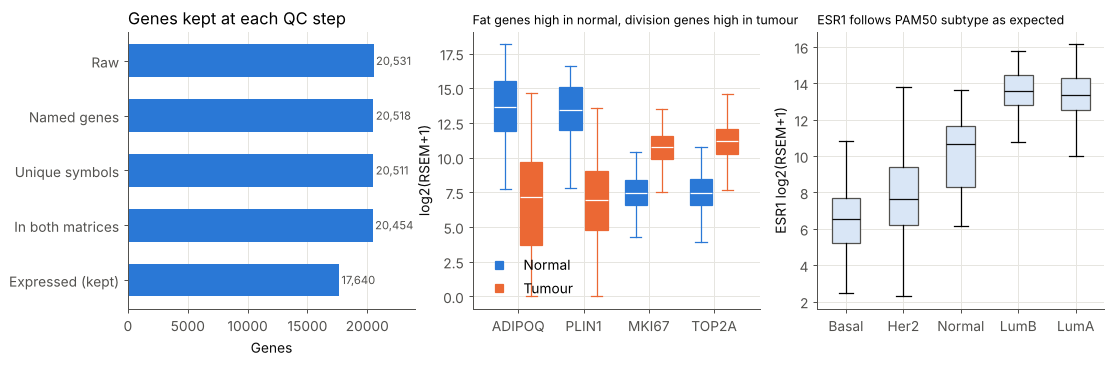

In [8]:
# STAGE 3 (Ibrahim): QC figure - genes kept per step, biology checks, ESR1 by subtype.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ax = axes[0]
steps = qc_table.iloc[[0, 2, 3, 4, 5]]
ax.barh(["Raw", "Named genes", "Unique symbols", "In both matrices", "Expressed (kept)"][::-1], steps.genes.values[::-1], color=NORMAL_C, height=.6)
for i, v in enumerate(steps.genes.values[::-1]): ax.text(v + 200, i, f"{v:,}", va="center", fontsize=9, color=MUTED)
ax.set_xlim(0, 24000); ax.set_xlabel("Genes"); ax.set_title("Genes kept at each QC step", loc="left"); ax.grid(axis="y", visible=False)
ax = axes[1]
gs4 = ["ADIPOQ", "PLIN1", "MKI67", "TOP2A"]
for off, mask, c, nm in [(-.2, N, NORMAL_C, "Normal"), (.2, T, TUMOUR_C, "Tumour")]:
    bp = ax.boxplot([expr.loc[mask, g] for g in gs4], positions=np.arange(4) + off, widths=.34, patch_artist=True, showfliers=False, medianprops={"color": "white"})
    for b in bp["boxes"]: b.set_facecolor(c); b.set_edgecolor(c)
    for w in bp["whiskers"] + bp["caps"]: w.set_color(c)
    ax.plot([], [], "s", color=c, label=nm)
ax.set_xticks(range(4)); ax.set_xticklabels(gs4); ax.set_ylabel("log2(RSEM+1)"); ax.legend(loc="lower left")
ax.set_title("Fat genes high in normal, division genes high in tumour", loc="left", fontsize=10)
ax = axes[2]
order_s = ["BRCA_Basal", "BRCA_Her2", "BRCA_Normal", "BRCA_LumB", "BRCA_LumA"]
ax.boxplot([expr.loc[sub[sub.subtype == s].index, "ESR1"] for s in order_s], showfliers=False, patch_artist=True,
           boxprops={"facecolor": "#d9e6f6", "edgecolor": MUTED}, medianprops={"color": INK})
ax.set_xticks(range(1, 6)); ax.set_xticklabels([s.replace("BRCA_", "") for s in order_s]); ax.set_ylabel("ESR1 log2(RSEM+1)")
ax.set_title("ESR1 follows PAM50 subtype as expected", loc="left", fontsize=10)
save(fig, D1, "qc_overview")

**Interpretation.**
- We removed unnamed rows and merged duplicate symbols, then filtered out genes that are barely expressed. The before/after table shows exactly what was removed. **All 158 DDR genes survive** the filters. Genes that TCGA stores under older symbols (e.g. H2AFX for H2AX, MRE11A for MRE11) were recovered through aliases.
- **The data match known biology.** Adipocyte genes are much higher in normal samples, proliferation genes are higher in tumours, ESR1 is highest in luminal subtypes and lowest in Basal, and ERBB2 peaks in HER2-enriched tumours. The labels and normalisation can be trusted.
- **Suspicious points to keep in mind:**
  1. Strong class imbalance (1,082 tumours vs 114 normals). We use balanced metrics later.
  2. All 114 normals came from only 6 of the 40 hospitals (tissue source sites), so hospital could confound the label. We test this with a leave-hospital-out check in Stage 7.
  3. "Normal" means tissue *adjacent* to a tumour, not healthy breast.
  4. Some tumours are PAM50 *Normal-like* and may look like normal tissue.
  5. Each patient contributes both a tumour and a normal sample, so cross-validation must be **grouped by patient** to avoid leakage.

## Stage 4 · Exploratory data analysis
*Owner: Alvin Kimani (167148)*

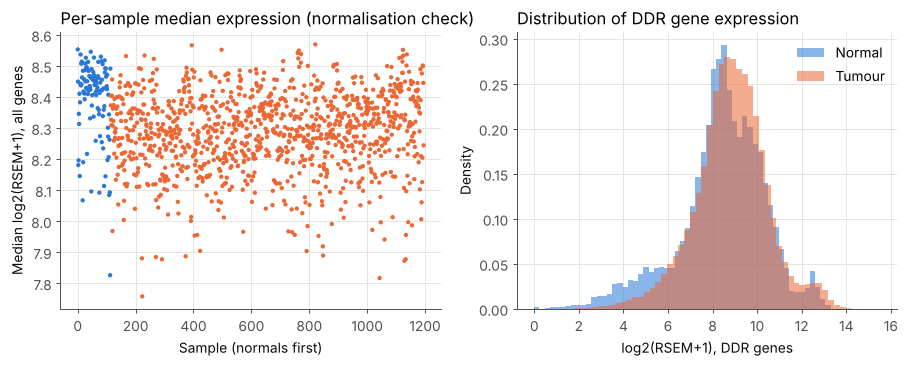

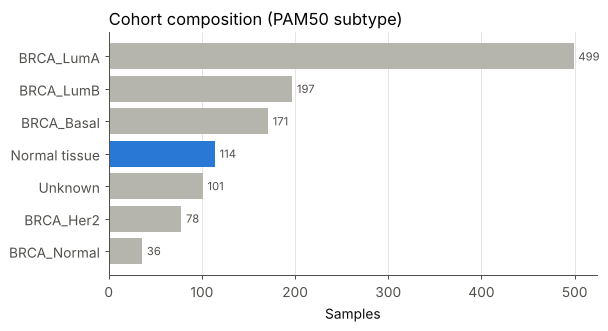

In [9]:
# STAGE 4 (Alvin): EDA plots - per-sample medians (normalisation check), expression distributions, cohort make-up.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
order = meta.sort_values(["label", "patient"]).index
# Median expression of every sample; a failed sample would stand out as an outlier
sample_med = expr.loc[order].median(axis=1)
ax.scatter(range(len(order)), sample_med, s=6, c=np.where(meta.loc[order].label == 1, TUMOUR_C, NORMAL_C))
ax.set_xlabel("Sample (normals first)"); ax.set_ylabel("Median log2(RSEM+1), all genes")
ax.set_title("Per-sample median expression (normalisation check)", loc="left")
ax = axes[1]
# Overlaid histograms of repair-gene expression, normal vs tumour
for lab, c, nm in [(0, NORMAL_C, "Normal"), (1, TUMOUR_C, "Tumour")]:
    vals = ddr[meta.label == lab].values.ravel()
    ax.hist(vals, bins=60, density=True, alpha=0.55, color=c, label=nm)
ax.set_xlabel("log2(RSEM+1), DDR genes"); ax.set_ylabel("Density"); ax.legend()
ax.set_title("Distribution of DDR gene expression", loc="left")
save(fig, D2, "eda_1_distributions")

fig, ax = plt.subplots(figsize=(7, 3.5))
# How many samples of each PAM50 subtype (and normal tissue) we have
sc = meta.subtype.fillna("Unknown").value_counts()
ax.barh(sc.index[::-1], sc.values[::-1], color=[NORMAL_C if s == "Normal tissue" else "#b5b4ad" for s in sc.index[::-1]])
for i, v in enumerate(sc.values[::-1]): ax.text(v + 5, i, str(v), va="center", fontsize=9, color=MUTED)
ax.set_xlabel("Samples"); ax.set_title("Cohort composition (PAM50 subtype)", loc="left"); ax.grid(axis="y", visible=False)
save(fig, D2, "eda_2_cohort")

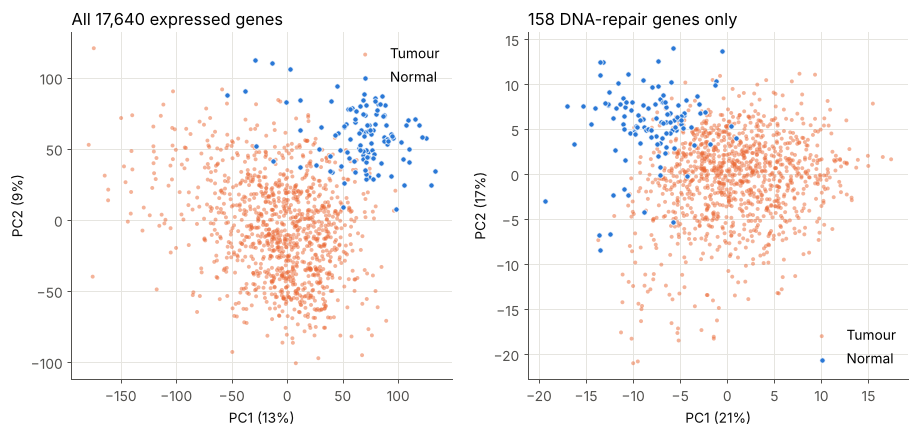

Variance explained by first 5 PCs (DDR genes): [0.211 0.174 0.059 0.044 0.031]


In [10]:
# STAGE 4 (Alvin): PCA - can tumour and normal be told apart in 2-D, using all genes vs repair genes only?
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Standardise each gene, then project samples onto the first 2 principal components
for ax, X, title in [(axes[0], expr, f"All {expr.shape[1]:,} expressed genes"), (axes[1], ddr, "158 DNA-repair genes only")]:
    Z = StandardScaler().fit_transform(X); pca = PCA(2, random_state=SEED).fit(Z); P = pca.transform(Z)
    ax.scatter(P[T, 0], P[T, 1], s=10, c=TUMOUR_C, alpha=0.5, edgecolor="none", label="Tumour")
    ax.scatter(P[N, 0], P[N, 1], s=18, c=NORMAL_C, edgecolor="white", linewidth=0.6, label="Normal")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}%)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}%)")
    ax.set_title(title, loc="left"); ax.legend()
save(fig, D2, "eda_3_pca")
# How much variation the first 5 components explain (repair genes)
pca_ddr = PCA(5).fit(StandardScaler().fit_transform(ddr))
print("Variance explained by first 5 PCs (DDR genes):", np.round(pca_ddr.explained_variance_ratio_, 3))

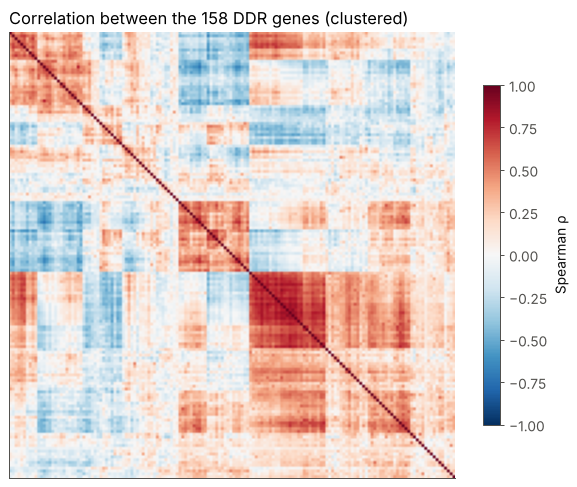

Median |ρ| between DDR gene pairs: 0.181


In [11]:
# STAGE 4 (Alvin): clustered Spearman correlation heatmap of the 158 repair genes.
corr = ddr.corr(method="spearman")
import scipy.cluster.hierarchy as sch
# Hierarchical clustering puts genes that move together next to each other
link = sch.linkage(corr, "average"); idx = sch.leaves_list(link)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.iloc[idx, idx], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.7, label="Spearman ρ")
ax.set_title("Correlation between the 158 DDR genes (clustered)", loc="left")
save(fig, D2, "eda_4_correlation_heatmap")
print("Median |ρ| between DDR gene pairs:", round(np.median(np.abs(corr.values[np.triu_indices(len(corr), 1)])), 3))

**Interpretation.**
- Per-sample medians sit in a narrow band (about 7.8–8.6 log2 units) across all 1,196 samples. There are no failed libraries or normalisation outliers, so no sample needs removing. The DDR expression distributions overlap heavily, with differences concentrated in specific genes rather than a global shift.
- The cohort is mostly Luminal A. Normals make up only 9.5% of samples.
- **PCA separates tumour from normal even on DDR genes alone.** Normals form a tight cluster at one edge, while tumours spread widely. That suggests tumours are more heterogeneous and that DDR genes carry tumour-vs-normal signal (H1).
- The correlation heatmap shows a large block of strongly co-expressed DDR genes. Stage 6 looks at what that block is.

## Stage 5 · Core analysis: differential expression
*Owner: Alvin Kimani (167148)*

- **Unpaired test:** Mann-Whitney U (non-parametric, so robust to the skewed RNA-seq distribution and unequal group sizes) on all 1,196 samples.
- **Paired test:** Wilcoxon signed-rank on the 114 patient-matched tumour/normal pairs, which controls for patient and hospital.
- **Multiple testing:** Benjamini-Hochberg false discovery rate (FDR) across the 158 genes.
- **Effect size:** log2 fold change (difference of mean log2 expression).

In [12]:
# STAGE 5 (Alvin): differential expression of each repair gene, tumour vs normal.
# log2 fold change = mean(tumour) - mean(normal) on the log2 scale; +1 means twice as high in tumours
lfc = ddr[T].mean() - ddr[N].mean()
# Mann-Whitney U test per gene (non-parametric, handles skew and 1,082 vs 114 group sizes)
p_mw = stats.mannwhitneyu(ddr[T], ddr[N], axis=0).pvalue
# Paired analysis: line up each patient's tumour with the SAME patient's normal (114 pairs)
pairs = meta[meta.paired & (meta.label == 0)].patient
tum_ids = meta[(meta.label == 1) & meta.paired].reset_index().set_index("patient").loc[pairs, "index"].values
nor_ids = meta[meta.label == 0].reset_index().set_index("patient").loc[pairs, "index"].values
# Within-patient difference, tumour minus normal, for every gene
diff = ddr.loc[tum_ids].values - ddr.loc[nor_ids].values
# Wilcoxon signed-rank test on the paired differences
p_wx = stats.wilcoxon(diff, axis=0).pvalue
# Results table; FDR = Benjamini-Hochberg corrected p-values across the 158 tests
de = pd.DataFrame({"gene": ddr.columns, "pathway": [GENE_TO_PATHWAY[g] for g in ddr.columns],
    "mean_normal": ddr[N].mean().values, "mean_tumour": ddr[T].mean().values, "log2FC": lfc.values,
    "fold_change": 2 ** lfc.values, "p_mannwhitney": p_mw, "FDR": multipletests(p_mw, method="fdr_bh")[1],
    "paired_median_log2FC": np.median(diff, 0), "pct_pairs_up": (diff > 0).mean(0) * 100,
    "p_wilcoxon_paired": p_wx, "FDR_paired": multipletests(p_wx, method="fdr_bh")[1]})
# Label each gene: up >= 2-fold, down >= 2-fold, smaller change, or not significant
de["call"] = np.select([(de.FDR < .05) & (de.log2FC >= 1), (de.FDR < .05) & (de.log2FC <= -1), de.FDR < .05],
                       ["Up ≥2×", "Down ≥2×", "Changed <2×"], "Not significant")
de = de.sort_values("FDR"); de.round(6).to_csv(f"{D2}/results/differential_expression_ddr.csv", index=False)
# Headline counts for the interpretation
summary = pd.Series({"Genes tested": len(de), "FDR < 0.05 (unpaired)": int((de.FDR < .05).sum()),
    "FDR < 0.05 (paired, 114 pairs)": int((de.FDR_paired < .05).sum()), "Up (any size)": int(((de.FDR < .05) & (de.log2FC > 0)).sum()),
    "Down (any size)": int(((de.FDR < .05) & (de.log2FC < 0)).sum()), "Up ≥ 2-fold": int((de.call == "Up ≥2×").sum()),
    "Down ≥ 2-fold": int((de.call == "Down ≥2×").sum())})
display(summary.to_frame("count"))
# Top 12 risers
de.sort_values("log2FC", ascending=False).head(12)[["gene", "pathway", "log2FC", "fold_change", "FDR", "pct_pairs_up", "FDR_paired"]].round(4)

,count
Genes tested,158
FDR < 0.05 (unpaired),145
"FDR < 0.05 (paired, 114 pairs)",134
Up (any size),101
Down (any size),44
Up ≥ 2-fold,29
Down ≥ 2-fold,3


,gene,pathway,log2FC,fold_change,FDR,pct_pairs_up,FDR_paired
32,EXO1,Mismatch repair,3.5772,11.9357,0.0,98.2456,0.0
10,NEIL3,Base excision repair,3.3963,10.5289,0.0,99.1228,0.0
119,UBE2T,Fanconi anaemia pathway,3.1249,8.7238,0.0,99.1228,0.0
76,RAD54L,Homologous recombination,3.0254,8.1419,0.0,96.4912,0.0
155,CLSPN,DDR signalling & checkpoints,2.8854,7.3893,0.0,97.3684,0.0
93,RECQL4,Homologous recombination,2.8558,7.2391,0.0,96.4912,0.0
130,POLQ,Translesion synthesis,2.5887,6.0156,0.0,94.7368,0.0
69,RAD51,Homologous recombination,2.5549,5.8763,0.0,98.2456,0.0
96,RMI2,Homologous recombination,2.4755,5.5617,0.0,99.1228,0.0
87,EME1,Homologous recombination,2.3253,5.0118,0.0,96.4912,0.0


In [13]:
# STAGE 5 (Alvin): the genes that fall most in tumours.
de.sort_values("log2FC").head(6)[["gene", "pathway", "log2FC", "fold_change", "FDR", "pct_pairs_up", "FDR_paired"]].round(4)

,gene,pathway,log2FC,fold_change,FDR,pct_pairs_up,FDR_paired
125,REV3L,Translesion synthesis,-1.2218,0.4288,0.0,12.2807,0.0
136,SHPRH,Translesion synthesis,-1.0958,0.4679,0.0,18.4211,0.0
16,APLF,Base excision repair,-1.0178,0.4939,0.0,15.7895,0.0
131,POLN,Translesion synthesis,-0.7805,0.5821,0.0,34.2105,0.0
70,RAD51B,Homologous recombination,-0.7350,0.6008,0.0,30.7018,0.0
140,ATM,DDR signalling & checkpoints,-0.7159,0.6088,0.0,18.4211,0.0


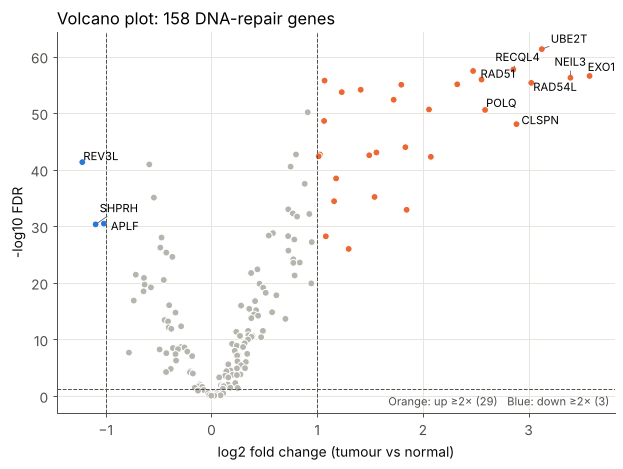

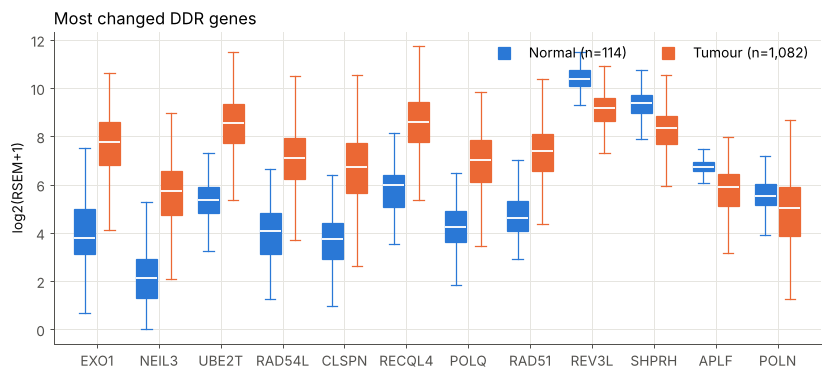

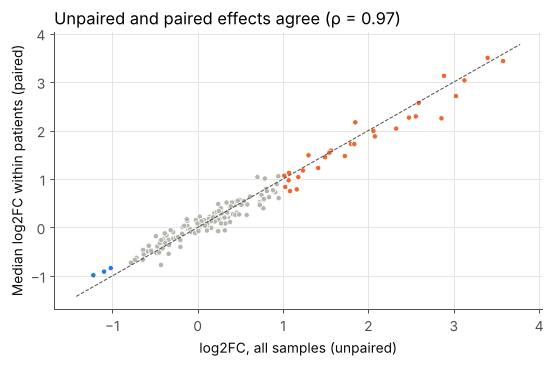

In [14]:
# STAGE 5 (Alvin): volcano plot, top-gene boxplots, and paired-vs-unpaired agreement.
from adjustText import adjust_text
fig, ax = plt.subplots(figsize=(8, 5.5))
# y-axis of the volcano plot: -log10(FDR); higher = more significant
nlp = -np.log10(de.FDR.clip(lower=1e-300))
col = np.select([de.call == "Up ≥2×", de.call == "Down ≥2×"], [TUMOUR_C, NORMAL_C], "#b5b4ad")
ax.scatter(de.log2FC, nlp, c=col, s=30, edgecolor="white", linewidth=0.8)
lab = pd.concat([de[de.FDR < .05].nlargest(8, "log2FC"), de[de.FDR < .05].nsmallest(3, "log2FC")])
# Label the strongest risers and fallers without overlapping text
texts = [ax.text(r.log2FC, -np.log10(max(r.FDR, 1e-300)), r.gene, fontsize=9) for _, r in lab.iterrows()]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6))
for x in (-1, 1): ax.axvline(x, color=MUTED, lw=0.8, ls="--")
ax.axhline(-np.log10(0.05), color=MUTED, lw=0.8, ls="--")
ax.set_xlabel("log2 fold change (tumour vs normal)"); ax.set_ylabel("-log10 FDR")
ax.set_title("Volcano plot: 158 DNA-repair genes", loc="left")
ax.text(0.99, 0.02, f"Orange: up ≥2× ({(de.call=='Up ≥2×').sum()})   Blue: down ≥2× ({(de.call=='Down ≥2×').sum()})",
        transform=ax.transAxes, ha="right", fontsize=9, color=MUTED)
save(fig, D2, "de_1_volcano")

# Boxplots of the 8 biggest risers and 4 biggest fallers
top = list(de[de.FDR < .05].nlargest(8, "log2FC").gene) + list(de[de.FDR < .05].nsmallest(4, "log2FC").gene)
fig, ax = plt.subplots(figsize=(11, 4.5)); pos = np.arange(len(top))
for off, mask, c, nm in [(-.2, N, NORMAL_C, "Normal (n=114)"), (.2, T, TUMOUR_C, "Tumour (n=1,082)")]:
    bp = ax.boxplot([ddr.loc[mask, g] for g in top], positions=pos + off, widths=.34, patch_artist=True, showfliers=False,
                    medianprops={"color": "white", "lw": 1.5})
    for b in bp["boxes"]: b.set_facecolor(c); b.set_edgecolor(c)
    for w in bp["whiskers"] + bp["caps"]: w.set_color(c)
    ax.plot([], [], "s", color=c, label=nm, ms=9)
ax.set_xticks(pos); ax.set_xticklabels(top); ax.set_ylabel("log2(RSEM+1)"); ax.legend(ncol=2, loc="upper right")
ax.set_title("Most changed DDR genes", loc="left")
save(fig, D2, "de_2_top_genes")

fig, ax = plt.subplots(figsize=(7, 4))
# If paired and unpaired fold changes agree, differences between patients don't drive the result
ax.scatter(de.log2FC, de.paired_median_log2FC, s=18, c=col, edgecolor="white", linewidth=0.6)
lim = [de.log2FC.min() - .2, de.log2FC.max() + .2]; ax.plot(lim, lim, color=MUTED, lw=.8, ls="--")
ax.set_xlabel("log2FC, all samples (unpaired)"); ax.set_ylabel("Median log2FC within patients (paired)")
r_pair = stats.spearmanr(de.log2FC, de.paired_median_log2FC).statistic
ax.set_title(f"Unpaired and paired effects agree (ρ = {r_pair:.2f})", loc="left")
save(fig, D2, "de_3_paired_vs_unpaired")

**Interpretation (O1).**
- **H1 is supported.** 145 of 158 DDR genes differ significantly (FDR < 0.05), and 134 stay significant in the paired test on 114 patients. The change is not a side-effect of comparing different people or hospitals: paired and unpaired fold changes agree almost perfectly.
- The change is **mostly upward**. 29 genes rise at least 2-fold, led by **EXO1 (~12×), NEIL3, UBE2T, RAD54L, CLSPN, RECQL4, POLQ and RAD51**. In nearly every patient the tumour beats the matched normal for these genes.
- Only 3 genes fall at least 2-fold: **REV3L, SHPRH and APLF**. These are damage-tolerance and end-joining accessory genes.
- With n = 1,196, even tiny shifts reach significance, so we focus on fold change as well as FDR.

## Stage 6 · Biological interpretation
*Owner: Latifah Jaafar (167074)*

Three interpretation methods, each linked back to the question:
1. **Pathway enrichment:** which repair pathways are over-represented among strongly up-regulated genes (Fisher's exact test, BH-FDR), plus a per-sample pathway activity score.
2. **Co-expression network (NetworkX):** which DDR genes move together in tumours, and which genes are hubs.
3. **Proliferation and literature comparison:** is the DDR rise explained by cell division?

In [15]:
# STAGE 6 (Latifah): pathway activity scores, pathway enrichment, and genome-wide comparison.
# up = genes rising >= 2-fold; universe = all 158 repair genes
up = set(de[de.call == "Up ≥2×"].gene); universe = set(de.gene)
rows = []
for pw, gs in DDR_PATHWAYS.items():
    gs = [g for g in gs if g in universe]
    # 2x2 table for Fisher's exact test: in pathway & up / in pathway & not up / ...
    a = len(set(gs) & up); b = len(gs) - a; c = len(up) - a; d = len(universe) - a - b - c
    # One-sided Fisher test: does this pathway hold MORE risers than chance?
    odds, p = stats.fisher_exact([[a, b], [c, d]], alternative="greater")
    # Pathway activity score = mean z-score of the pathway's genes, per sample
    z = (ddr[gs] - ddr[gs].mean()) / ddr[gs].std(); score = z.mean(axis=1)
    from sklearn.metrics import roc_auc_score
    # Also test the score tumour vs normal, and how well the score alone separates them (AUC)
    rows.append({"pathway": pw, "genes": len(gs), "up_2fold": a, "pct_up": 100 * a / len(gs), "odds_ratio": odds,
                 "p_enrichment": p, "score_diff_T_minus_N": score[T].mean() - score[N].mean(),
                 "p_score": stats.mannwhitneyu(score[T], score[N]).pvalue, "auc_score_alone": roc_auc_score(meta.label, score)})
enr = pd.DataFrame(rows)
# Correct both sets of p-values for multiple testing
enr["FDR_enrichment"] = multipletests(enr.p_enrichment, method="fdr_bh")[1]
enr["FDR_score"] = multipletests(enr.p_score, method="fdr_bh")[1]
enr = enr.sort_values("score_diff_T_minus_N", ascending=False)
enr.round(4).to_csv(f"{D3}/results/pathway_enrichment.csv", index=False)

# genome-wide context: are DDR genes more often strongly up than an average gene?
# Same differential test on all 17,640 genes, to compare repair genes against the genome
g_lfc = expr[T].mean() - expr[N].mean(); g_fdr = multipletests(stats.mannwhitneyu(expr[T], expr[N], axis=0).pvalue, method="fdr_bh")[1]
g_up = (g_fdr < .05) & (g_lfc.values >= 1); is_ddr = expr.columns.isin(ddr.columns)
# 2x2 table: repair vs other genes, strongly up vs not
tab = [[int(g_up[is_ddr].sum()), int((~g_up[is_ddr]).sum())], [int(g_up[~is_ddr].sum()), int((~g_up[~is_ddr]).sum())]]
or_g, p_g = stats.fisher_exact(tab)
print(f"Strongly up-regulated (≥2×, FDR<0.05): DDR genes {100*tab[0][0]/is_ddr.sum():.1f}% vs all other genes {100*tab[1][0]/(~is_ddr).sum():.1f}%  "
      f"→ odds ratio {or_g:.2f}, Fisher p = {p_g:.1e}")
enr[["pathway", "genes", "up_2fold", "pct_up", "odds_ratio", "FDR_enrichment", "score_diff_T_minus_N", "auc_score_alone", "FDR_score"]].round(3)

Strongly up-regulated (≥2×, FDR<0.05): DDR genes 17.4% vs all other genes 7.9%  → odds ratio 2.48, Fisher p = 1.7e-04


,pathway,genes,up_2fold,pct_up,odds_ratio,FDR_enrichment,score_diff_T_minus_N,auc_score_alone,FDR_score
5,Fanconi anaemia pathway,15,5,33.333,2.479,0.512,0.847,0.894,0.000
3,Homologous recombination,31,12,38.710,4.087,0.020,0.743,0.883,0.000
0,Base excision repair,25,5,20.000,1.135,1.000,0.687,0.926,0.000
1,Mismatch repair,16,3,18.750,1.030,1.000,0.568,0.818,0.000
8,DDR signalling & checkpoints,18,3,16.667,0.877,1.000,0.410,0.774,0.000
7,Direct reversal,3,0,0.000,0.000,1.000,0.044,0.533,0.285
4,Non-homologous end joining,9,0,0.000,0.000,1.000,0.043,0.549,0.109
2,Nucleotide excision repair,28,0,0.000,0.000,1.000,-0.010,0.501,0.978
6,Translesion synthesis,13,1,7.692,0.348,1.000,-0.111,0.408,0.002


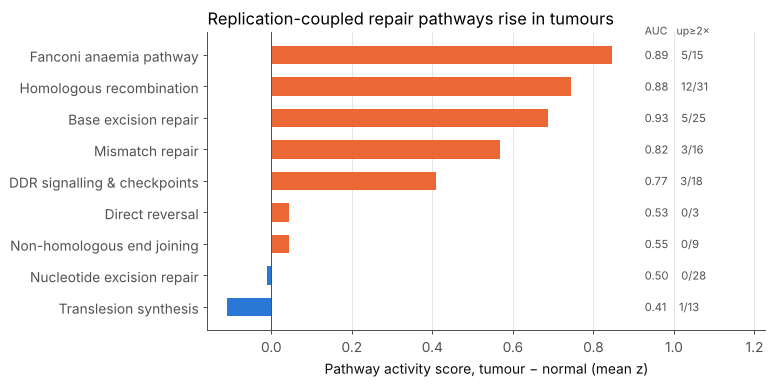

In [16]:
# STAGE 6 (Latifah): bar chart of pathway score changes, with each pathway's AUC and number of risers.
fig, ax = plt.subplots(figsize=(8, 4.3))
e = enr.sort_values("score_diff_T_minus_N")
ax.barh(e.pathway, e.score_diff_T_minus_N, color=[TUMOUR_C if d > 0 else NORMAL_C for d in e.score_diff_T_minus_N], height=.6)
xr = e.score_diff_T_minus_N.max() + .08
for i, (a, u, n) in enumerate(zip(e.auc_score_alone, e.up_2fold, e.genes)):
    ax.text(xr, i, f"{a:.2f}    {u}/{n}", va="center", fontsize=9, color=MUTED)
ax.text(xr, len(e) - .35, "AUC   up≥2×", fontsize=8.5, color=MUTED); ax.set_xlim(right=xr + .3)
ax.axvline(0, color=MUTED, lw=.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("Pathway activity score, tumour − normal (mean z)")
ax.set_title("Replication-coupled repair pathways rise in tumours", loc="left")
save(fig, D3, "bio_1_pathways")

Network (tumours, Spearman ρ ≥ 0.6): 69 genes, 318 edges, 8 modules


,module,size,pct_up_2fold,top_pathways,hub_genes
0,1,25,16.0,"DDR signalling & checkpoints, Homologous recom...","CLSPN, FANCB, TOPBP1, XRCC2, BRIP1, MSH2"
1,2,22,81.8,"Homologous recombination, Mismatch repair, Fan...","BLM, EXO1, POLQ, NEIL3, RAD51AP1, FANCI"
2,3,6,50.0,"Homologous recombination, Base excision repair...","POLD1, RECQL4, H2AX, GTF2H4, LIG1, XRCC3"
3,4,5,20.0,"Base excision repair, Direct reversal, Nucleot...","MPG, PNKP, XAB2, MGMT, NTHL1"


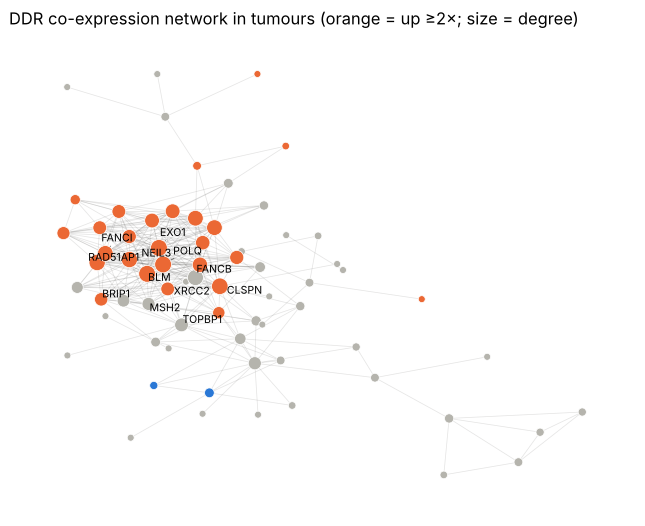

In [17]:
# STAGE 6 (Latifah): co-expression network of repair genes in tumours, built with NetworkX.
import networkx as nx
# Spearman correlation between repair genes, tumours only (co-regulation within cancer)
ct = ddr[T].corr(method="spearman"); THR = 0.6
# Nodes = genes (with pathway and DE call); edges = pairs with correlation >= 0.6
G = nx.Graph()
for g in ct.columns: G.add_node(g, pathway=GENE_TO_PATHWAY[g], call=de.set_index("gene").loc[g, "call"])
for i, a in enumerate(ct.columns):
    for b in ct.columns[i + 1:]:
        if ct.loc[a, b] >= THR: G.add_edge(a, b, weight=ct.loc[a, b])
# Drop genes with no strong partner
G.remove_nodes_from([n for n in list(G) if G.degree(n) == 0])
# Greedy modularity finds modules: groups of genes more connected to each other than to the rest
comms = sorted(nx.algorithms.community.greedy_modularity_communities(G, weight="weight"), key=lambda m: (-len(m), sorted(m)))
# Degree = number of links; high-degree genes are the hubs
deg = pd.Series(dict(G.degree())).sort_index().sort_values(ascending=False, kind="stable")  # ties broken alphabetically
print(f"Network (tumours, Spearman ρ ≥ {THR}): {G.number_of_nodes()} genes, {G.number_of_edges()} edges, {len(comms)} modules")
mod_rows = []
# Describe the 4 largest modules: size, % risers, main pathways, hub genes
for k, c in enumerate(comms[:4], 1):
    c = sorted(c); calls = de.set_index("gene").loc[c, "call"]
    mod_rows.append({"module": k, "size": len(c), "pct_up_2fold": round(100 * (calls == "Up ≥2×").mean(), 1),
                     "top_pathways": ", ".join(pd.Series([GENE_TO_PATHWAY[g] for g in c]).value_counts().sort_index().sort_values(ascending=False, kind="stable").head(3).index),
                     "hub_genes": ", ".join(deg[c].sort_index().sort_values(ascending=False, kind="stable").head(6).index)})
modules = pd.DataFrame(mod_rows); modules.to_csv(f"{D3}/results/network_modules.csv", index=False)
deg.rename("degree").to_csv(f"{D3}/results/network_hub_degree.csv")
display(modules)

fig, ax = plt.subplots(figsize=(9, 7))
# Draw the network: orange = up >= 2-fold, node size = number of links
pos = nx.kamada_kawai_layout(G)
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.15, width=0.6, edge_color=MUTED)
ncol = [TUMOUR_C if G.nodes[n]["call"] == "Up ≥2×" else NORMAL_C if G.nodes[n]["call"] == "Down ≥2×" else "#b5b4ad" for n in G]
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[25 + 6 * G.degree(n) for n in G], node_color=ncol, edgecolors="white", linewidths=0.6)
lab_nodes = list(dict.fromkeys(list(deg.head(8).index) + list(modules.hub_genes.str.split(", ").explode().head(12))))
texts = [ax.text(pos[n][0], pos[n][1], n, fontsize=8.5) for n in lab_nodes]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.5))
ax.set_axis_off(); ax.set_title("DDR co-expression network in tumours (orange = up ≥2×; size = degree)", loc="left")
save(fig, D3, "bio_2_network")

Median Spearman ρ with proliferation score, within tumours: up≥2× genes 0.72 | all other DDR genes 0.12


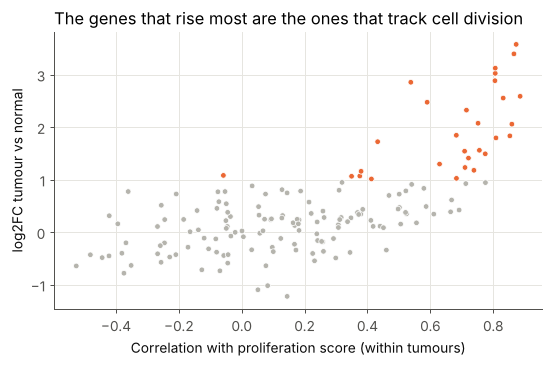

In [18]:
# STAGE 6 (Latifah): are the risers simply tracking cell division? Correlate each gene with a proliferation score.
# Classic proliferation markers; their mean = proliferation score per sample
prolif_genes = ["MKI67", "TOP2A", "CCNB1", "BUB1", "AURKA"]
prolif = expr[prolif_genes].mean(axis=1)
up_genes = list(de[de.call == "Up ≥2×"].gene)
# Spearman correlation of each repair gene with proliferation, within tumours
rho = pd.Series({g: stats.spearmanr(ddr.loc[T, g], prolif[T]).statistic for g in ddr.columns})
print(f"Median Spearman ρ with proliferation score, within tumours: up≥2× genes {rho[up_genes].median():.2f} | "
      f"all other DDR genes {rho.drop(up_genes).median():.2f}")
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(rho, de.set_index("gene").loc[rho.index, "log2FC"], s=20,
           c=[TUMOUR_C if g in up_genes else "#b5b4ad" for g in rho.index], edgecolor="white", linewidth=.6)
ax.set_xlabel("Correlation with proliferation score (within tumours)"); ax.set_ylabel("log2FC tumour vs normal")
ax.set_title("The genes that rise most are the ones that track cell division", loc="left")
save(fig, D3, "bio_3_proliferation")
rho.rename("rho_proliferation").to_csv(f"{D3}/results/ddr_vs_proliferation.csv")

**Interpretation (O2).**
- **Pathway level.** Activity scores for the Fanconi anaemia pathway, homologous recombination, base excision repair and mismatch repair rise significantly (FDR < 0.001). Homologous recombination is also significantly enriched among the ≥2-fold risers (12 of 31 genes, odds ratio 4.1, FDR = 0.02). Nucleotide excision repair, non-homologous end joining and direct reversal hardly change, and translesion synthesis falls slightly. The repair systems that rise are the ones **coupled to DNA replication**: they fix stalled forks, mismatches and damage made during S-phase.
- **Genome-wide context.** DDR genes are about 2.5× more likely than an average gene to be strongly up-regulated (Fisher p ≈ 2e-4). Repair is a specifically boosted process in breast tumours, not just random background.
- **Network.** In tumours (ρ ≥ 0.6), one module of 22 genes holds most of the risers (82% are up ≥2-fold). Its hubs are EXO1, BLM, POLQ, NEIL3, RAD51AP1 and FANCI. A second module gathers checkpoint and HR genes (CLSPN, TOPBP1, BRIP1). The up-regulated genes switch on together as one programme rather than one by one.
- **Proliferation.** Within tumours, the ≥2-fold risers correlate strongly with a proliferation score (median ρ = 0.72), while the other DDR genes barely do (ρ = 0.12). Much of the rise reflects **faster-dividing tumour cells** that need more repair capacity, together with **replication stress** in cancer cells.
- **Literature.** This agrees with reports that HR and FA genes (RAD51, BRCA1, FANCI, UBE2T) are over-expressed in proliferative and basal-like breast cancer and linked to poor prognosis. POLQ over-expression in breast cancer is also well documented and makes it a drug target. Low REV3L and APLF fit reports of reduced damage tolerance in some tumours.

## Stage 7 · Machine learning
*Owner: Caleb Kipchirchir (169391)*

**Task.** Binary classification, tumour (1) vs normal (0), using **only the 158 DDR genes** as features.

**Validation design.** 5-fold `StratifiedGroupKFold` grouped by **patient** (a patient's tumour and normal never sit on both sides of a split), repeated 3 times with different shuffles. Classes are imbalanced (9.5:1), so we report **balanced accuracy, specificity, MCC and PR-AUC for the normal class** alongside ROC-AUC.

**Models and why**
| Model | Why we chose it |
|---|---|
| Logistic regression, L2 (main model) | Linear and interpretable (each coefficient is a gene's weight). Standardised inputs and L2 regularisation cope with correlated genes. Probabilities are well calibrated. Easy to deploy in a browser. |
| Logistic regression, L1 | Sparse: it picks a small subset of genes automatically. Tests whether few genes are enough. |
| Random forest | Non-linear, captures gene interactions, needs no scaling. A strong tree-based comparison. |
| SVM with RBF kernel | Non-linear margin classifier that works well with many correlated features and a small minority class. |

**Baselines**
1. **Majority-class dummy:** always predicts "tumour" (the floor).
2. **Stratified dummy:** random guesses at the class ratio.
3. **Single gene (MKI67):** one proliferation marker, a biological baseline.
4. **100 random gene sets of 158 genes:** tests whether *DNA-repair* genes are special.

All models use `class_weight="balanced"` so the minority class (normal) is not ignored.

In [19]:
# STAGE 7 (Caleb): train 4 models + 3 baselines with patient-grouped cross-validation and compare them.
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, recall_score,
                             matthews_corrcoef, roc_curve, confusion_matrix)
# y = labels (1 tumour, 0 normal); groups = patient IDs for grouped CV
y = meta.label.values; groups = meta.patient.values

# Imbalance-aware metrics: ROC-AUC, PR-AUC for normals, balanced accuracy, sensitivity, specificity, MCC
def metrics(yt, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(yt, prob), "PR-AUC (normal)": average_precision_score(1 - yt, 1 - prob),
            "Balanced acc.": balanced_accuracy_score(yt, pred), "Sensitivity": recall_score(yt, pred),
            "Specificity": recall_score(1 - yt, 1 - pred), "MCC": matthews_corrcoef(yt, pred)}

# 5-fold StratifiedGroupKFold, repeated: keeps class ratio per fold and a patient's samples in ONE fold
def cv_predict(X, make, reps=3, grp=groups, y_=None, seed0=0):
    X = np.asarray(X); y_ = y if y_ is None else y_; oofs = []
    for r in range(reps):
        oof = np.zeros(len(y_))
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=seed0 + r).split(X, y_, grp):
            # Fit on training folds, predict the held-out fold (out-of-fold predictions = honest scores)
            oof[te] = make().fit(X[tr], y_[tr]).predict_proba(X[te])[:, 1]
        oofs.append(oof)
    res = pd.DataFrame([metrics(y_, o) for o in oofs])
    return res.mean(), res.std(), np.mean(oofs, 0)

# The 4 algorithms. class_weight='balanced' makes each normal count ~9.5x so it isn't ignored
MODELS = {
  # Main model: standardise genes, L2-regularised logistic regression (interpretable, calibrated)
  "Logistic regression (L2)": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)),
  # Sparse version: L1 pushes most gene weights to zero
  "Logistic regression (L1)": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.05, penalty="l1", solver="liblinear", class_weight="balanced", max_iter=5000)),
  # 400 decision trees; captures non-linear gene interactions
  "Random forest": lambda: RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
  # Support vector machine with an RBF (non-linear) kernel
  "SVM (RBF)": lambda: make_pipeline(StandardScaler(), SVC(C=1, class_weight="balanced", probability=True, random_state=SEED)),
}
# Baselines: always 'tumour', random guessing, and one proliferation gene (MKI67)
BASELINES = {
  "Baseline: majority class": (ddr, lambda: DummyClassifier(strategy="most_frequent")),
  "Baseline: stratified random": (ddr, lambda: DummyClassifier(strategy="stratified", random_state=SEED)),
  "Baseline: MKI67 only": (expr[["MKI67"]], lambda: make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced"))),
}
rows, oof = {}, {}
# Evaluate baselines, then the 4 models, all with the same CV
for name, (X, make) in BASELINES.items():
    m, s, o = cv_predict(X, make); rows[name] = m
for name, make in MODELS.items():
    m, s, o = cv_predict(ddr, make); rows[name] = m; oof[name] = o
results = pd.DataFrame(rows).T.round(4)
results.to_csv(f"{D4}/results/model_comparison.csv")
results

,ROC-AUC,PR-AUC (normal),Balanced acc.,Sensitivity,Specificity,MCC
Baseline: majority class,0.5000,0.0953,0.5000,1.0000,0.0000,0.0000
Baseline: stratified random,0.4803,0.0934,0.4803,0.9168,0.0439,-0.0427
Baseline: MKI67 only,0.9478,0.6932,0.8944,0.8940,0.8947,0.6014
Logistic regression (L2),0.9981,0.9770,0.9827,0.9858,0.9795,0.9202
Logistic regression (L1),0.9963,0.9645,0.9674,0.9553,0.9795,0.8065
Random forest,0.9953,0.9599,0.9278,0.9960,0.8596,0.8983
SVM (RBF),0.9974,0.9646,0.9696,0.9948,0.9444,0.9417


Confusion matrix (out-of-fold), rows = truth [Normal, Tumour]:
 [[ 111    3]
 [  14 1068]]

Misclassified samples by PAM50 subtype:
subtype
BRCA_Normal      9
BRCA_LumA        3
Normal tissue    3
Unknown          2


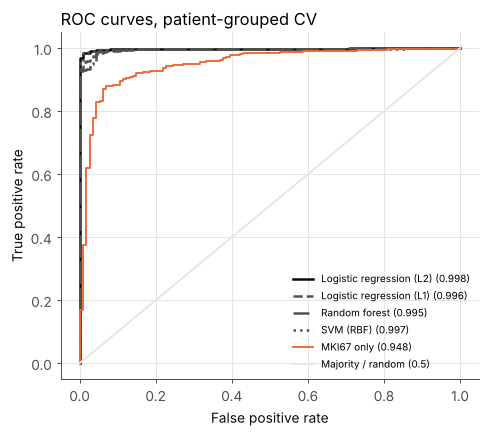

In [20]:
# STAGE 7 (Caleb): confusion matrix, which samples are misclassified, and ROC curves.
MAIN = "Logistic regression (L2)"
# Rows = true class (normal, tumour), columns = predicted class, at a 0.5 threshold
cm = confusion_matrix(y, (oof[MAIN] >= .5).astype(int))
print("Confusion matrix (out-of-fold), rows = truth [Normal, Tumour]:\n", cm)
# List the misclassified samples with their subtype and hospital
mis = meta.assign(p_tumour=oof[MAIN]); mis = mis[(mis.p_tumour >= .5).astype(int) != mis.label]
print("\nMisclassified samples by PAM50 subtype:"); print(mis.subtype.fillna("Unknown").value_counts().to_string())
mis[["group", "subtype", "site", "p_tumour"]].round(3).to_csv(f"{D4}/results/misclassified.csv")

fig, ax = plt.subplots(figsize=(6, 5))
for (name, o), ls in zip(oof.items(), ["-", "--", "-.", ":"]):
    fpr, tpr, _ = roc_curve(y, o); ax.plot(fpr, tpr, ls, lw=2, color=INK if ls == "-" else MUTED, label=f"{name} ({results.loc[name,'ROC-AUC']:.3f})")
fpr, tpr, _ = roc_curve(y, expr["MKI67"]); ax.plot(fpr, tpr, color=TUMOUR_C, lw=1.5, label=f"MKI67 only ({results.loc['Baseline: MKI67 only','ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=GRID, label="Majority / random (0.5)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("ROC curves, patient-grouped CV", loc="left")
save(fig, D4, "ml_1_roc")

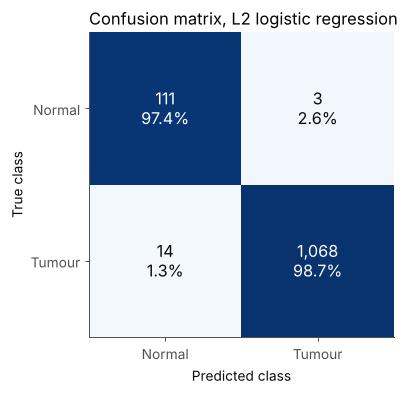

Accuracy 0.986 | sensitivity 0.987 | specificity 0.974


In [21]:
# STAGE 7 (Caleb): confusion matrix of the final model as a figure (counts and row percentages).
# Out-of-fold predictions averaged over the 3 CV repeats, threshold 0.5.
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(5.2, 4.4))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100   # % of each true class
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
labels = ["Normal", "Tumour"]
for i in range(2):
    for j in range(2):
        # White text on the dark (correct) cells, dark text on the light (error) cells
        ax.text(j, i, f"{cm[i, j]:,}\n{cm_pct[i, j]:.1f}%", ha="center", va="center", fontsize=13,
                color="white" if cm_pct[i, j] > 50 else INK)
ax.set_xticks([0, 1]); ax.set_xticklabels(labels); ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.grid(False)
ax.set_title("Confusion matrix, L2 logistic regression", loc="left")
save(fig, D4, "ml_4_confusion_matrix")
print(f"Accuracy {np.trace(cm)/cm.sum():.3f} | sensitivity {cm[1,1]/cm[1].sum():.3f} | specificity {cm[0,0]/cm[0].sum():.3f}")


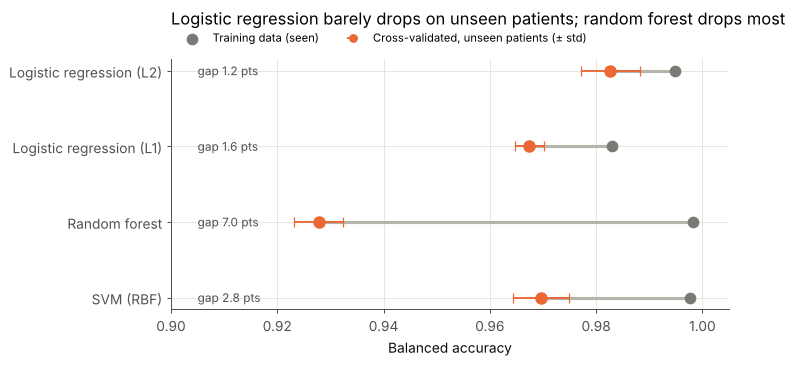

,train_bal_acc,cv_bal_acc,cv_bal_acc_std,gap_bal_acc,train_auc,cv_auc,cv_auc_std
model,,,,,,,
Logistic regression (L2),0.9949,0.9827,0.0056,0.0122,0.9991,0.9981,0.0001
Logistic regression (L1),0.9829,0.9674,0.0027,0.0155,0.9976,0.9963,0.0001
Random forest,0.9982,0.9278,0.0046,0.0703,0.9999,0.9953,0.0003
SVM (RBF),0.9977,0.9696,0.0053,0.0281,0.9987,0.9974,0.0001


In [22]:
# STAGE 7 (Caleb): overfitting check - compare each model's score on its own training data with its cross-validated score.
# A model that overfits scores near-perfectly on training data but much worse on unseen folds (a large gap).
# We also report the spread (std) across the 3 CV repeats: a small spread means the result does not hinge on one lucky split.
gap_rows = []
for name, make in MODELS.items():
    train_prob = make().fit(ddr.values, y).predict_proba(ddr.values)[:, 1]      # scored on the data it learned from
    tr = metrics(y, train_prob)
    cv_mean, cv_std, _ = cv_predict(ddr, make)                                     # scored on held-out patients only
    gap_rows.append({"model": name, "train_bal_acc": tr["Balanced acc."], "cv_bal_acc": cv_mean["Balanced acc."],
                     "cv_bal_acc_std": cv_std["Balanced acc."], "gap_bal_acc": tr["Balanced acc."] - cv_mean["Balanced acc."],
                     "train_auc": tr["ROC-AUC"], "cv_auc": cv_mean["ROC-AUC"], "cv_auc_std": cv_std["ROC-AUC"]})
gap = pd.DataFrame(gap_rows).set_index("model").round(4)
gap.to_csv(f"{D4}/results/overfitting_check.csv")

# Dumbbell chart: grey dot = score on training data, orange dot = cross-validated score (with spread across repeats).
# The length of the line between them is the overfitting gap.
fig, ax = plt.subplots(figsize=(8, 3.6))
ys = np.arange(len(gap))[::-1]
for yv, (name, r) in zip(ys, gap.iterrows()):
    ax.plot([r.cv_bal_acc, r.train_bal_acc], [yv, yv], color="#b5b4ad", lw=2.5, zorder=1)
    ax.errorbar(r.cv_bal_acc, yv, xerr=r.cv_bal_acc_std, fmt="o", ms=9, color=TUMOUR_C, capsize=4, zorder=3)
    ax.scatter(r.train_bal_acc, yv, s=70, color="#7a7a74", zorder=2)
    ax.text(0.905, yv, f"gap {r.gap_bal_acc * 100:.1f} pts", va="center", fontsize=9.5, color=MUTED)
ax.set_yticks(ys); ax.set_yticklabels(gap.index); ax.set_xlim(0.90, 1.005)
ax.set_xlabel("Balanced accuracy")
ax.scatter([], [], s=70, color="#7a7a74", label="Training data (seen)")
ax.errorbar([], [], xerr=[], fmt="o", color=TUMOUR_C, label="Cross-validated, unseen patients (± std)")
ax.legend(loc="lower left", fontsize=9, bbox_to_anchor=(0, 1.02), ncol=2)
ax.set_title("Logistic regression barely drops on unseen patients; random forest drops most", loc="left", pad=28)
save(fig, D4, "ml_5_overfitting_check")
gap


In [23]:
# STAGE 7 (Caleb): robustness checks.
# Robustness 1: patient-matched pairs only. Robustness 2: hold out whole hospitals (tissue source sites).
# Check 1: train and test only on the 114 patient-matched pairs (228 samples)
pm = meta.paired.values
m_pair, _, _ = cv_predict(ddr.values[pm], MODELS[MAIN], grp=groups[pm], y_=y[pm])
oof_site = np.zeros(len(y))
from sklearn.model_selection import GroupKFold
# Check 2: hold out whole hospitals, so test samples come from hospitals never seen in training
for tr, te in GroupKFold(5).split(ddr, y, meta.site.values):
    oof_site[te] = MODELS[MAIN]().fit(ddr.values[tr], y[tr]).predict_proba(ddr.values[te])[:, 1]
robust = pd.DataFrame({"Main CV (patient-grouped)": results.loc[MAIN], "Matched pairs only (228 samples)": m_pair,
                       "Leave-hospital-out": pd.Series(metrics(y, oof_site))}).T.round(4)
robust.to_csv(f"{D4}/results/robustness.csv"); robust

,ROC-AUC,PR-AUC (normal),Balanced acc.,Sensitivity,Specificity,MCC
Main CV (patient-grouped),0.9981,0.9770,0.9827,0.9858,0.9795,0.9202
Matched pairs only (228 samples),0.9996,0.9996,0.9898,0.9912,0.9883,0.9795
Leave-hospital-out,0.9975,0.9671,0.9804,0.9871,0.9737,0.9222


Random 158-gene sets: AUC mean 0.9991 (range 0.9985–0.9999); balanced acc. mean 0.992
DDR genes: AUC 0.9981 → beats 0% of random sets


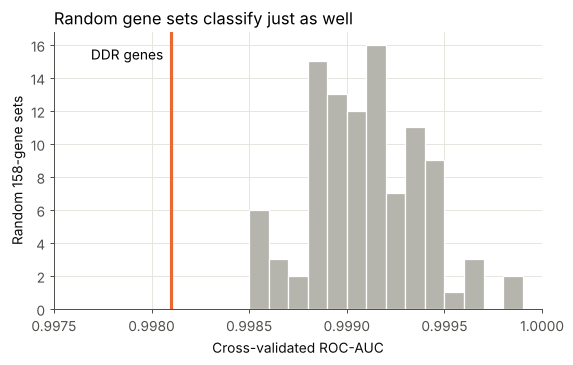

In [24]:
# STAGE 7 (Caleb): baseline 4 - are repair genes special? Compare against 100 random sets of 158 genes.
# Baseline 4: random gene sets of the same size
# Pool = expressed genes that are NOT repair genes
rng = np.random.default_rng(SEED); pool = expr.columns[~expr.columns.isin(ddr.columns)]
rand_auc, rand_bacc = [], []
# Each round: pick 158 random genes, run the same model and CV, record AUC and balanced accuracy
for i in range(100):
    cols = rng.choice(pool, size=ddr.shape[1], replace=False)
    m, _, _ = cv_predict(expr[cols], MODELS[MAIN], reps=1, seed0=100 + i)
    rand_auc.append(m["ROC-AUC"]); rand_bacc.append(m["Balanced acc."])
ddr_auc = results.loc[MAIN, "ROC-AUC"]
print(f"Random 158-gene sets: AUC mean {np.mean(rand_auc):.4f} (range {min(rand_auc):.4f}–{max(rand_auc):.4f}); "
      f"balanced acc. mean {np.mean(rand_bacc):.3f}")
print(f"DDR genes: AUC {ddr_auc:.4f} → beats {100*np.mean(np.array(rand_auc) < ddr_auc):.0f}% of random sets")
pd.DataFrame({"auc": rand_auc, "balanced_acc": rand_bacc}).to_csv(f"{D4}/results/random_geneset_baseline.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(rand_auc, bins=np.arange(0.9975, 1.00001, 0.0001), color="#b5b4ad", edgecolor="white")
ax.axvline(ddr_auc, color=TUMOUR_C, lw=2.5); ax.set_xlim(0.9975, 1.0)
ax.text(ddr_auc, ax.get_ylim()[1] * .9, "DDR genes  ", ha="right")
ax.set_xlabel("Cross-validated ROC-AUC"); ax.set_ylabel("Random 158-gene sets")
ax.set_title("Random gene sets classify just as well", loc="left")
save(fig, D4, "ml_2_random_baseline")

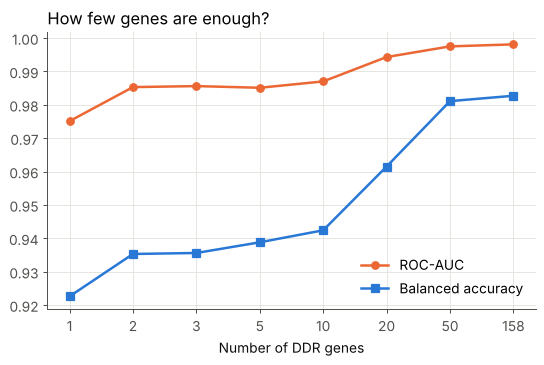

,ROC-AUC,PR-AUC (normal),Balanced acc.,Sensitivity,Specificity,MCC
n_genes,,,,,,
1,0.9751,0.8162,0.9226,0.9125,0.9327,0.6638
2,0.9853,0.9067,0.9353,0.9319,0.9386,0.7138
3,0.9856,0.9060,0.9356,0.9384,0.9327,0.7273
5,0.9851,0.9001,0.9388,0.9390,0.9386,0.7327
10,0.9870,0.9156,0.9424,0.9433,0.9415,0.7466
20,0.9943,0.9538,0.9615,0.9640,0.9591,0.8225
50,0.9975,0.9753,0.9811,0.9855,0.9766,0.9171
158,0.9981,0.9770,0.9827,0.9858,0.9795,0.9202


In [25]:
# STAGE 7 (Caleb): how few genes are enough? Panels of 1 to 158 genes.
# How few genes are enough? Genes ranked by |Welch t| INSIDE each training fold (no selection leakage).
# Genes are ranked by |Welch t| INSIDE each training fold only, so the test fold never influences selection
def panel_cv(k, reps=3):
    res = []
    for r in range(reps):
        o = np.zeros(len(y))
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(ddr, y, groups):
            t = stats.ttest_ind(ddr.iloc[tr][y[tr] == 1], ddr.iloc[tr][y[tr] == 0], equal_var=False).statistic
            top = ddr.columns[np.argsort(-np.abs(t))[:k]]
            o[te] = MODELS[MAIN]().fit(ddr.iloc[tr][top].values, y[tr]).predict_proba(ddr.iloc[te][top].values)[:, 1]
        res.append(metrics(y, o))
    return pd.DataFrame(res).mean()
panel = pd.DataFrame({k: panel_cv(k) for k in [1, 2, 3, 5, 10, 20, 50, 158]}).T.round(4)
panel.index.name = "n_genes"; panel.to_csv(f"{D4}/results/panel_size_curve.csv")
fig, ax = plt.subplots(figsize=(7, 4)); xs = range(len(panel))
ax.plot(xs, panel["ROC-AUC"], "-o", color=TUMOUR_C, lw=2, label="ROC-AUC")
ax.plot(xs, panel["Balanced acc."], "-s", color=NORMAL_C, lw=2, label="Balanced accuracy")
ax.set_xticks(xs); ax.set_xticklabels(panel.index); ax.set_xlabel("Number of DDR genes"); ax.legend(loc="lower right")
ax.set_title("How few genes are enough?", loc="left")
save(fig, D4, "ml_3_panel_size")
panel

In [26]:
# STAGE 7 (Caleb trains, Jude exports): final models refit on all data and saved for the web app and API.
# Final models, refit on all data, exported for deployment (stage owned by Jude, files in 5-jude-deployment/model)
import joblib
os.makedirs(f"{D5}/model", exist_ok=True)
# Final 158-gene model, trained on all 1,196 samples
final = MODELS[MAIN]().fit(ddr.values, y)
t_all = stats.ttest_ind(ddr[T], ddr[N], equal_var=False).statistic
# 10-gene panel = the 10 genes with the largest |t| on all data
panel_genes = list(ddr.columns[np.argsort(-np.abs(t_all))[:10]])
final_panel = MODELS[MAIN]().fit(ddr[panel_genes].values, y)
# Model weights per gene (correlated genes share weight, so read with care)
coef = pd.DataFrame({"gene": ddr.columns, "pathway": [GENE_TO_PATHWAY[g] for g in ddr.columns], "coefficient": final[-1].coef_[0]})
coef.reindex(coef.coefficient.abs().sort_values(ascending=False).index).round(4).to_csv(f"{D4}/results/model_coefficients.csv", index=False)
# joblib files are loaded by the Flask API
joblib.dump({"model": final, "genes": list(ddr.columns)}, f"{D5}/model/ddr158_logreg.joblib")
joblib.dump({"model": final_panel, "genes": panel_genes}, f"{D5}/model/ddr10_panel_logreg.joblib")

# export(): write everything the browser needs to rebuild the model: means, scales, weights, intercept
def export(model, gs, name, cv):
    s, l = model[0], model[-1]
    return {"name": name, "genes": gs, "pathways": [GENE_TO_PATHWAY[g] for g in gs], "mean": np.round(s.mean_, 5).tolist(),
            "scale": np.round(s.scale_, 5).tolist(), "coef": np.round(l.coef_[0], 6).tolist(), "intercept": round(float(l.intercept_[0]), 6),
            "normal_mean": np.round(ddr[N][gs].mean().values, 4).tolist(), "tumour_mean": np.round(ddr[T][gs].mean().values, 4).tolist(),
            "cv": {"roc_auc": float(cv["ROC-AUC"]), "balanced_acc": float(cv["Balanced acc."]), "sensitivity": float(cv["Sensitivity"]),
                   "specificity": float(cv["Specificity"])}, "input_units": "log2(RSEM normalized count + 1)"}
# 6 example samples (3 normal, 3 tumour) for the web app's demo buttons
ex_ids = list(meta[N].sample(3, random_state=1).index) + list(meta[T].sample(3, random_state=1).index)
model_json = {"full": export(final, list(ddr.columns), "All 158 DDR genes", results.loc[MAIN]),
              "panel": export(final_panel, panel_genes, "10-gene DDR panel", panel.loc[10]),
              "examples": [{"id": s, "truth": meta.loc[s, "group"], "values": {g: round(float(ddr.loc[s, g]), 3) for g in ddr.columns}} for s in ex_ids],
              "dataset": "TCGA-BRCA PanCancer Atlas (cBioPortal), 1,082 tumours + 114 normals"}
# model.json is embedded into the web app
json.dump(model_json, open(f"{D5}/model/model.json", "w"))
print("10-gene panel:", panel_genes)
print("Top 10 coefficients of the full model (correlated genes share weight, so these differ from the top DE genes):"); coef.reindex(coef.coefficient.abs().sort_values(ascending=False).index).head(10).round(3)

10-gene panel: ['UBE2T', 'PARP1', 'FEN1', 'RAD51', 'PCNA', 'EME1', 'NEIL3', 'RFC2', 'EXO1', 'FANCI']
Top 10 coefficients of the full model (correlated genes share weight, so these differ from the top DE genes):


,gene,pathway,coefficient
127,POLH,Translesion synthesis,0.393
114,FANCF,Fanconi anaemia pathway,0.387
85,RBBP8,Homologous recombination,-0.381
95,RMI1,Homologous recombination,0.366
16,APLF,Base excision repair,-0.355
107,POLM,Non-homologous end joining,0.348
48,RPA1,Nucleotide excision repair,-0.320
121,FAAP100,Fanconi anaemia pathway,0.317
106,NHEJ1,Non-homologous end joining,-0.301
96,RMI2,Homologous recombination,0.283


**Interpretation (O3).**
- **H2 is supported against the standard baselines.** The majority-class dummy has balanced accuracy 0.50 and MCC 0. One proliferation gene (MKI67) reaches AUC ≈ 0.95. The 158 DDR genes reach **ROC-AUC 0.998, balanced accuracy 0.98 and MCC 0.92** with logistic regression. Logistic regression has the best AUC and balanced accuracy. The SVM is close (highest MCC), while random forest catches tumours well but misses normals (specificity ≈ 0.86).
- **Robust.** Performance holds on the 114 patient-matched pairs (AUC ≈ 1.00) and when whole hospitals are held out (AUC ≈ 0.997), so the model is not learning the hospital or batch.
- **Compact.** A 10-gene panel (UBE2T, PARP1, FEN1, RAD51, PCNA, EME1, NEIL3, RFC2, EXO1, FANCI) keeps AUC ≈ 0.99. Genes were picked inside each training fold, so this estimate is honest.
- **Errors make biological sense.** Most misclassified tumours are PAM50 *Normal-like*, a subtype whose expression resembles normal breast.
- **Negative finding, which matters.** **Random gene sets of the same size classify just as well** (AUC ≈ 0.999). Tumour vs normal is such a large biological difference that almost any 158 genes separate the groups. DDR genes *can* classify, but this is **not evidence that DNA repair is uniquely diagnostic**.

## Deployment
*Owner: Jude Makau (166487)*

The two final models (`5-jude-deployment/model/`) power two front ends:
- **Web app on GitHub Pages** (`5-jude-deployment/web/index.html`). The logistic regression runs in the browser in JavaScript (standardise → dot product → sigmoid). No server is needed, and it shows the genes that drove each prediction.
- **REST API** (`5-jude-deployment/api/`). Flask + gunicorn in Docker with `/health`, `/genes` and `/predict` (JSON or CSV). It checks inputs (missing genes, raw counts) and comes with automated tests.

The cell below checks that the exported JSON gives exactly the same probabilities as scikit-learn, so the browser app matches the notebook.

In [27]:
# DEPLOYMENT (Jude): prove the browser maths gives exactly the same probabilities as scikit-learn.
mj = json.load(open(f"{D5}/model/model.json"))
# Same steps as the JavaScript: standardise -> weighted sum + intercept -> sigmoid
def js_like(values, m):
    z = (np.array([values[g] for g in m["genes"]]) - np.array(m["mean"])) / np.array(m["scale"])
    return 1 / (1 + np.exp(-(m["intercept"] + z @ np.array(m["coef"]))))
# Compare both probabilities for every example sample
for e in mj["examples"]:
    p_js = js_like(e["values"], mj["full"]); p_sk = final.predict_proba(ddr.loc[[e["id"]]].values)[0, 1]
    print(f'{e["id"]}  truth={e["truth"]:6s}  browser={p_js:.4f}  sklearn={p_sk:.4f}')

TCGA-E2-A1L7-11  truth=Normal  browser=0.0240  sklearn=0.0240
TCGA-BH-A0E1-11  truth=Normal  browser=0.0027  sklearn=0.0027
TCGA-BH-A18Q-11  truth=Normal  browser=0.0069  sklearn=0.0069
TCGA-D8-A27T-01  truth=Tumour  browser=0.9973  sklearn=0.9973
TCGA-C8-A275-01  truth=Tumour  browser=1.0000  sklearn=1.0000
TCGA-D8-A1JB-01  truth=Tumour  browser=0.9775  sklearn=0.9775


## Stage 8 · Conclusions
*Owners: all members*

| Objective | Answer |
|---|---|
| **O1:** Do DDR genes differ between tumour and normal? | **Yes.** 145/158 genes differ (FDR < 0.05) and 134 remain significant within patients. 29 rise ≥2-fold (EXO1, NEIL3, UBE2T, RAD54L, RAD51, POLQ ...); only 3 fall ≥2-fold (REV3L, SHPRH, APLF). |
| **O2:** What does it mean biologically? | Replication-coupled repair (HR, Fanconi anaemia, BER, MMR) rises, and the risers form one co-expressed module (hubs EXO1, BLM, POLQ). HR is significantly enriched among the strongest risers. NER and NHEJ barely change. DDR genes are 2.5× enriched among strongly up-regulated genes. The rise tracks proliferation and replication stress in tumour cells. |
| **O3:** Can DDR genes alone classify? | **Yes.** ROC-AUC 0.998 and balanced accuracy 0.98 with patient-grouped CV, far above the dummy baselines, and robust to matched pairs and held-out hospitals. 10 genes are nearly enough. **But** random gene sets do equally well, so the classification power is not specific to DNA repair. |
| **O4:** Deploy the model | Done. GitHub Pages web app plus a Dockerised Flask API, both serving the same verified model. |

**Limitations**
- One cohort and one platform (TCGA RNA-seq) with no external validation set, so performance on microarray or other pipelines is unknown.
- "Normal" tissue is adjacent to a tumour and may carry field effects. It is not healthy breast.
- Strong class imbalance (114 normals), and normals came from fewer hospitals.
- Expression is bulk tissue, so tumour purity and fat content shift gene levels.
- Correlation, not causation: we cannot say repair up-regulation drives cancer.

**Future steps**
1. Validate on an independent dataset (e.g. GEO microarray cohorts such as GSE15852).
2. Adjust for proliferation and purity to find repair changes beyond cell division.
3. Ask a harder, clinically useful question with the same genes: predict PAM50 subtype or homologous-recombination deficiency (relevant to PARP inhibitors).
4. Add STRING protein-interaction data to the network analysis.